Task 2.1

In [12]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def data_generator(n_samples=10, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.random.uniform(0, 0.5, n_samples)
    np.random.shuffle(t)
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t*(2*A*np.cos(phi+omega*t))) 

    return t, y

data = data_generator(n_samples=10, m=1, k=500, mu=5)

data

(array([0.30055751, 0.36599697, 0.18727006, 0.02904181, 0.43308807,
        0.35403629, 0.29932924, 0.47535715, 0.07800932, 0.07799726]),
 array([0.48384469, 1.16497676, 1.33648727, 0.93902119, 2.96082264,
        0.91560024, 0.48263256, 1.85877017, 1.0099699 , 1.00991531]))

In [19]:
import torch
from torch import nn
import torch.nn.functional as F


num_hidden = 10
num_features = 1
num_output = 1

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[2] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        self.W_1 = nn.Parameter(torch.randn(num_hidden, num_features)) 
        self.b_1 = nn.Parameter(torch.randn(num_hidden))
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(num_output, num_hidden))
        self.b_2 = nn.Parameter(torch.randn(num_output))
        
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        x = F.linear(x, self.W_1, self.b_1)
        
        # second layer (to be completed as an exercise)
        x = F.tanh(x)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        x = F.linear(x, self.W_2, self.b_2)
        return x 

net = Net()

In [22]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = torch.optim.LBFGS(net.parameters(), lr=0.01)


In [ ]:



num_epochs = 1000
train_losses = []

# Convert data to tensors
tr_input = torch.from_numpy(data[0]).float().reshape(-1, 1)
print(tr_input)
tr_targets = torch.from_numpy(data[1]).float().reshape(-1, 1)

# Training loop
for e in range(num_epochs):

    optimizer.zero_grad()

    # Prediction
    tr_output = net(tr_input)

    # Calculate loss
    tr_loss = criterion(tr_output, tr_targets)

    # Backpropagation
    tr_loss.backward()

    # Update weights
    optimizer.step()

    train_losses.append(tr_loss.data.numpy())

    if e % 100 == 0:
        print("Epoch %i, Train Cost: %0.6f" % (e, tr_loss.item()))
print()

tensor([[0.3006],
        [0.3660],
        [0.1873],
        [0.0290],
        [0.4331],
        [0.3540],
        [0.2993],
        [0.4754],
        [0.0780],
        [0.0780]])
Epoch 0, Train Cost: 7.197968
Epoch 100, Train Cost: 0.376357
Epoch 200, Train Cost: 0.340723
Epoch 300, Train Cost: 0.327510
Epoch 400, Train Cost: 0.314157
Epoch 500, Train Cost: 0.297709
Epoch 600, Train Cost: 0.277415
Epoch 700, Train Cost: 0.255060
Epoch 800, Train Cost: 0.235071
Epoch 900, Train Cost: 0.221422


In [34]:
np.random.seed(42)

def data_generator(n_samples=100, m=1, k=500, mu=5):
    # Create covariates and response variable
    t = np.linspace(0, 1, n_samples+2)[1:-1]
    #np.random.shuffle(t)
    delta = mu/(2*m)
    omega_0=np.sqrt(k)
    omega= np.sqrt(omega_0**2-delta**2)
    phi=np.arctan(-delta/omega)
    A= 1/(2*np.cos(phi))
    y = np.exp(-delta*t*(2*A*np.cos(phi+omega*t))) 

    return t, y

data2 = data_generator(n_samples=100, m=1, k=500, mu=5)

data2

(array([0.00990099, 0.01980198, 0.02970297, 0.03960396, 0.04950495,
        0.05940594, 0.06930693, 0.07920792, 0.08910891, 0.0990099 ,
        0.10891089, 0.11881188, 0.12871287, 0.13861386, 0.14851485,
        0.15841584, 0.16831683, 0.17821782, 0.18811881, 0.1980198 ,
        0.20792079, 0.21782178, 0.22772277, 0.23762376, 0.24752475,
        0.25742574, 0.26732673, 0.27722772, 0.28712871, 0.2970297 ,
        0.30693069, 0.31683168, 0.32673267, 0.33663366, 0.34653465,
        0.35643564, 0.36633663, 0.37623762, 0.38613861, 0.3960396 ,
        0.40594059, 0.41584158, 0.42574257, 0.43564356, 0.44554455,
        0.45544554, 0.46534653, 0.47524752, 0.48514851, 0.4950495 ,
        0.5049505 , 0.51485149, 0.52475248, 0.53465347, 0.54455446,
        0.55445545, 0.56435644, 0.57425743, 0.58415842, 0.59405941,
        0.6039604 , 0.61386139, 0.62376238, 0.63366337, 0.64356436,
        0.65346535, 0.66336634, 0.67326733, 0.68316832, 0.69306931,
        0.7029703 , 0.71287129, 0.72277228, 0.73

In [35]:
te_input = torch.from_numpy(data2[0]).float().reshape(-1, 1)
te_target = torch.from_numpy(data2[1]).float().reshape(-1, 1)


with torch.no_grad():
    te_output = net(te_input)




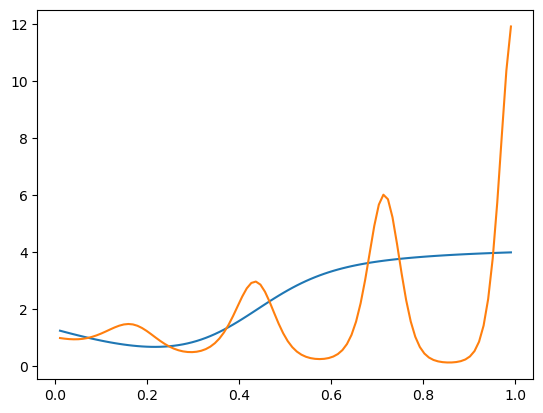

In [36]:
import matplotlib.pyplot as plt
plt.plot(te_input,te_output)
plt.plot(te_input,te_target)
plt.show()

it gets crazy since the net is only trained on the interval 0-0.5, so it does not know at all after this. 